# Multi-agent MPPI with handmade anchor paths

This example extends the central-obstacle scenario with four manually authored polygonal paths. The paths are inputs to MPPI; this notebook does not contain a global path-planning algorithm.

![Multi-agent anchor-path animation](anchor_path_multi_agent.gif)

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle, Polygon
import numpy as np
from IPython.display import Image, display

EXAMPLE_DIR = Path.cwd()
if not (EXAMPLE_DIR / 'utils.py').exists():
    EXAMPLE_DIR = EXAMPLE_DIR / 'example'
sys.path.insert(0, str(EXAMPLE_DIR))

import dyn_models
from params_names import *
import utils

## Scenario and anchor paths

Each agent starts at one cardinal side of the obstacle and must reach the opposite side. Its four-point anchor path takes it around the obstacle. These points are deliberately listed by hand.

In [2]:
AGENTS_NUM = 4
AGENT_RADIUS = 0.3
DT = 0.1

obstacles = [np.array([
    [-2.5, -1.5], [-1.5, -2.5], [1.5, -2.5], [2.5, -1.5],
    [2.5, 1.5], [1.5, 2.5], [-1.5, 2.5], [-2.5, 1.5],
], dtype=np.float64)]

start_states = np.array([
    [-6.0,  0.0,  0.82, 0.0, 0.0],
    [ 6.0,  0.0, -2.32, 0.0, 0.0],
    [ 0.0, -6.0,  2.32, 0.0, 0.0],
    [ 0.0,  6.0, -0.82, 0.0, 0.0],
], dtype=np.float64)
goal_states = np.array([
    [ 6.0,  0.0, -0.82, 0.0, 0.0],
    [-6.0,  0.0,  2.32, 0.0, 0.0],
    [ 0.0,  6.0,  0.82, 0.0, 0.0],
    [ 0.0, -6.0, -2.32, 0.0, 0.0],
], dtype=np.float64)

anchor_paths = [
    [(-6.0, 0.0), (-3.2,  3.2), ( 3.2,  3.2), ( 6.0, 0.0)],
    [( 6.0, 0.0), ( 3.2, -3.2), (-3.2, -3.2), (-6.0, 0.0)],
    [( 0.0,-6.0), (-3.2, -3.2), (-3.2,  3.2), ( 0.0, 6.0)],
    [( 0.0, 6.0), ( 3.2,  3.2), ( 3.2, -3.2), ( 0.0,-6.0)],
]

## Controller parameters

`ANCHOR_PATH_WEIGHT` scales the running distance-to-path cost. The ordinary goal and collision-avoidance costs remain active. `TERMINAL_LOOKAHEAD_DISTANCE` is also used as arc-length lookahead on the active anchor path.

In [3]:
default_agent_params = {
    AGENT_SIZE: AGENT_RADIUS,
    VISIBILITY_RADIUS: 30.0,
    DIFF_DRIVE_V_MAX: 1.0,
    DIFF_DRIVE_V_MIN: -0.01,
    DIFF_DRIVE_W_MAX: 2.0,
    DIFF_DRIVE_W_MIN: -2.0,
}
agents_params = [default_agent_params.copy() for _ in range(AGENTS_NUM)]
agent_models = [dyn_models.DiffDriveDyn() for _ in range(AGENTS_NUM)]

alg_params = {
    SAMPLE_BATCH_SIZE: 700,
    SAMPLE_TIME_STEPS: 20,
    TIME_STEP: DT,
    INIT_VALUE: np.zeros(2),
    CONTROL_MEAN: np.zeros(2),
    CONTROL_COV: np.diag([1.0, 6.0]),
    RUNNING_COST_WEIGH: 395.0,
    TERMINAL_WEIGHT: 1600.0,
    SOFTMAX_TEMPERATURE: 0.25,
    MA_COST_EN: True,
    MA_DIST_WEIGHT: 750.0,
    MA_COLLISION_WEIGHT: 1e7,
    MA_DIST_THREASHOLD: 3.5,
    USE_CAR_LIKE_DYN: False,
    K_ALPHA: -2.96,
    RAD_EPS: 0.05,
    VELOCITY_COST_WEIGHT: 0.5,
    TERMINAL_LOOKAHEAD_DISTANCE: 2.0,
    MA_EN_CLOSE_TO_GOAL_DIST: 1.0,
    MA_EN_CLOSE_TO_GOAL_TS: 3,
    ORCA_TIME_BOUNDARY: 1.0,
    ORCA_RESPONSIBILITY_FACTOR: 0.5,
    MA_EXCLUDE_COLLISION_TRAJ: True,
    VELOCITY_COST_CLOSE_TO_GOAL_DIST: 0.4,
    ANCHOR_PATH_WEIGHT: 1600.0,
}
exp_params = {
    EXP_TIME_STEP: DT,
    XY_GOAL_TOLERANCE: 0.3,
    MAX_EXP_STEPS: 250,
}

## Run the multi-agent experiment

In [4]:
success, collisions, steps, duration, log_state = utils.launch_mppi(
    start_states,
    goal_states,
    AGENTS_NUM,
    agents_params,
    alg_params,
    exp_params,
    agent_models,
    seed=7,
    obstacles=obstacles,
    anchor_paths=anchor_paths,
)
states = np.asarray(log_state)
print(f'success={success}, collisions={collisions}, steps={steps}, wall time={duration:.2f}s')

success=True, collisions=0.0, steps=177, wall time=5.18s


## Static result

Dashed lines are anchor paths; solid lines are executed trajectories.

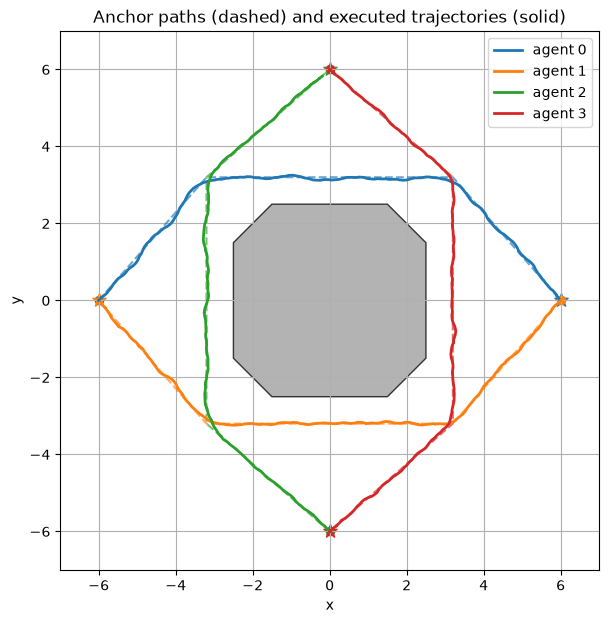

In [5]:
colors = plt.colormaps['tab10'](np.arange(AGENTS_NUM))

def draw_world(ax):
    for obstacle in obstacles:
        ax.add_patch(Polygon(obstacle, closed=True, facecolor='0.7', edgecolor='0.2'))
    for agent_id, anchor in enumerate(anchor_paths):
        anchor = np.asarray(anchor)
        ax.plot(anchor[:, 0], anchor[:, 1], '--', color=colors[agent_id],
                alpha=0.65, linewidth=1.5)
    ax.set(xlim=(-7, 7), ylim=(-7, 7), aspect='equal', xlabel='x', ylabel='y')
    ax.grid(True)

fig, ax = plt.subplots(figsize=(7, 7))
draw_world(ax)
for agent_id in range(AGENTS_NUM):
    ax.plot(states[:, agent_id, 0], states[:, agent_id, 1],
            color=colors[agent_id], linewidth=2, label=f'agent {agent_id}')
    ax.scatter(*start_states[agent_id, :2], color=colors[agent_id], marker='o')
    ax.scatter(*goal_states[agent_id, :2], color=colors[agent_id], marker='*', s=100)
ax.legend(loc='upper right')
ax.set_title('Anchor paths (dashed) and executed trajectories (solid)')
plt.show()

## Animated GIF

The anchor paths remain visible in every frame. The generated GIF is saved next to this notebook and displayed below.

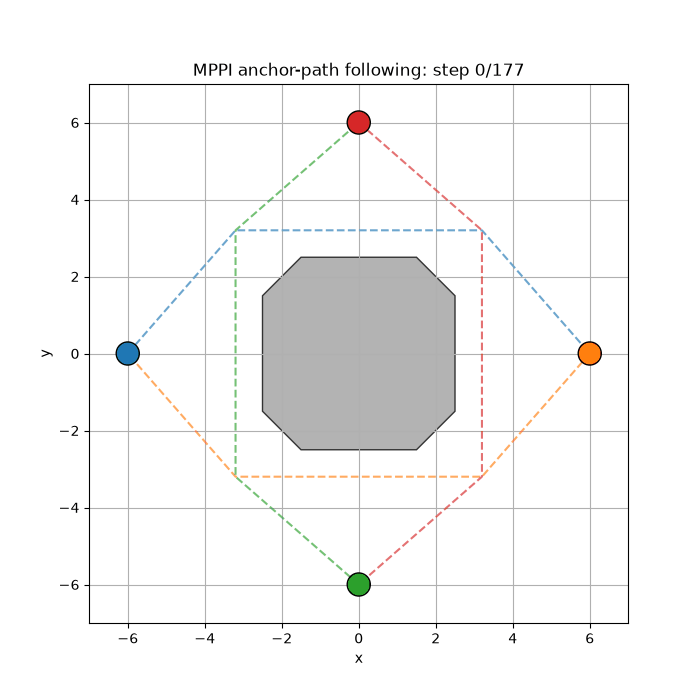

In [6]:
fig, ax = plt.subplots(figsize=(7, 7))

def animate(frame):
    ax.clear()
    draw_world(ax)
    for agent_id in range(AGENTS_NUM):
        color = colors[agent_id]
        ax.plot(states[:frame + 1, agent_id, 0], states[:frame + 1, agent_id, 1],
                color=color, linewidth=2)
        ax.add_patch(Circle(states[frame, agent_id, :2], AGENT_RADIUS,
                            facecolor=color, edgecolor='black', zorder=4))
        ax.scatter(*goal_states[agent_id, :2], color=color, marker='*', s=80, zorder=3)
    ax.set_title(f'MPPI anchor-path following: step {frame}/{len(states) - 1}')

animation = FuncAnimation(fig, animate, frames=len(states), interval=100)
GIF_PATH = EXAMPLE_DIR / 'anchor_path_multi_agent.gif'
animation.save(GIF_PATH, writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=str(GIF_PATH)))